Build a model to find whether the person will be dafaulter for loan
or not when income &baonce of the person is privited

In [36]:
import pandas as pd

In [37]:
data = pd.read_csv("C:/Users/Hajapure/OneDrive/Desktop/Default.csv")
data.head()

,default,student,balance,income
0,No,No,729.526495,44361.62507
1,No,Yes,817.180407,12106.13470
2,No,No,1073.549164,31767.13895
3,No,No,529.250605,35704.49394
4,No,No,785.655883,38463.49588


In [38]:
data['default'].value_counts()

default
No     9667
Yes     333
Name: count, dtype: int64

In [39]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 4 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   default  10000 non-null  str    
 1   student  10000 non-null  str    
 2   balance  10000 non-null  float64
 3   income   10000 non-null  float64
dtypes: float64(2), str(2)
memory usage: 312.6 KB


In [40]:
data.describe()

,balance,income
count,10000.000000,10000.000000
mean,835.374886,33516.981876
std,483.714985,13336.639563
min,0.000000,771.967729
25%,481.731105,21340.462905
50%,823.636973,34552.644800
75%,1166.308387,43807.729275
max,2654.322576,73554.233500


In [41]:
import matplotlib.pyplot as plt

{'whiskers': [<matplotlib.lines.Line2D at 0x1dc6dd66ad0>,
 'caps': [<matplotlib.lines.Line2D at 0x1dc6dd66d50>,
 'boxes': [<matplotlib.lines.Line2D at 0x1dc6dd66990>],
 'medians': [<matplotlib.lines.Line2D at 0x1dc6dd66fd0>],
 'fliers': [<matplotlib.lines.Line2D at 0x1dc6dd67110>],
 'means': []}

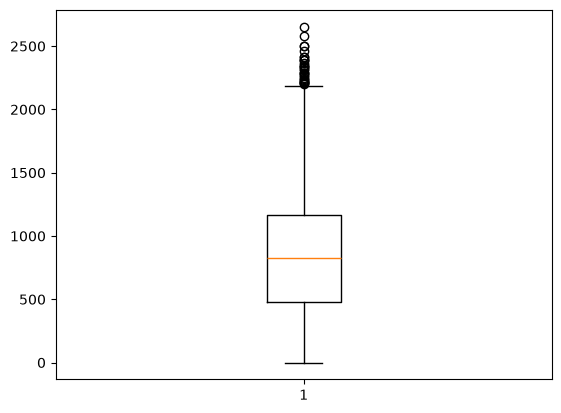

In [42]:
plt.boxplot(data['balance'])

{'whiskers': [<matplotlib.lines.Line2D at 0x1dc6ddddbd0>,
 'caps': [<matplotlib.lines.Line2D at 0x1dc6dddde50>,
 'boxes': [<matplotlib.lines.Line2D at 0x1dc6dddda90>],
 'medians': [<matplotlib.lines.Line2D at 0x1dc6ddde0d0>],
 'fliers': [<matplotlib.lines.Line2D at 0x1dc6ddde210>],
 'means': []}

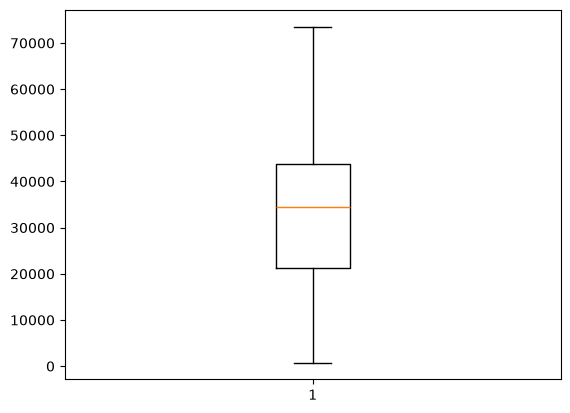

In [43]:
plt.boxplot(data['income'])

In [44]:
q3 = data['balance'].quantile(0.75)
q1 = data['balance'].quantile(0.25)

In [45]:
iqr = q3 - q1

In [46]:
ub = q3 +1.5 * iqr
lb = q1 - 1.5 * iqr

In [47]:
len(data[data['balance']> ub])

31

In [48]:
len(data[data['balance']< lb])

0

In [49]:
ub

np.float64(2193.1743093)

In [50]:
data.loc[data['balance']> ub,'balance'] = ub

In [51]:
len(data[data['balance']>ub])

0

{'whiskers': [<matplotlib.lines.Line2D at 0x1dc6dea1bd0>,
 'caps': [<matplotlib.lines.Line2D at 0x1dc6dea1e50>,
 'boxes': [<matplotlib.lines.Line2D at 0x1dc6dea1a90>],
 'medians': [<matplotlib.lines.Line2D at 0x1dc6dea20d0>],
 'fliers': [<matplotlib.lines.Line2D at 0x1dc6dea2210>],
 'means': []}

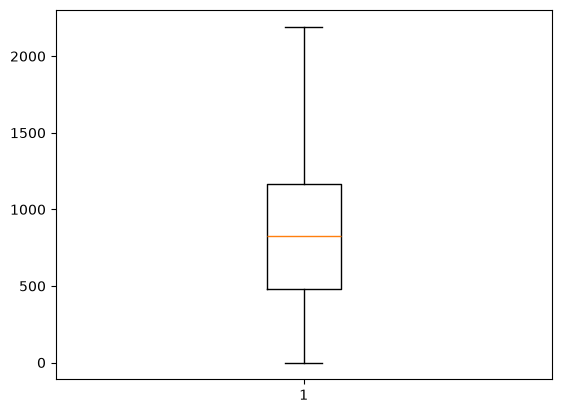

In [52]:
plt.boxplot(data['balance'])

In [53]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 4 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   default  10000 non-null  str    
 1   student  10000 non-null  str    
 2   balance  10000 non-null  float64
 3   income   10000 non-null  float64
dtypes: float64(2), str(2)
memory usage: 312.6 KB


In [54]:
data.drop('student', axis=1,inplace=True)

In [55]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 3 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   default  10000 non-null  str    
 1   balance  10000 non-null  float64
 2   income   10000 non-null  float64
dtypes: float64(2), str(1)
memory usage: 234.5 KB


In [56]:
X = data.drop('default', axis=1)
y = data['default']

In [57]:
from sklearn.preprocessing import Normalizer

In [58]:
NS = Normalizer()

In [59]:
X_ns = NS.fit_transform(X)

In [60]:
from sklearn.model_selection import train_test_split

In [63]:
X_train,X_test,y_train, y_test= train_test_split(X_ns,y,random_state=7,test_size=0.2)

In [64]:
from sklearn.neighbors import KNeighborsClassifier

In [68]:
model= KNeighborsClassifier(n_neighbors=5)

In [69]:
model.fit(X_train,y_train)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[object](2,)","['No','Yes']"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


In [70]:
train_pred = model.predict(X_train)

##Confusion Matrix

In [72]:
from sklearn.metrics import accuracy_score

In [73]:
accuracy_score(y_train,train_pred)

0.967875

In [74]:
y_train .value_counts()

default
No     7734
Yes     266
Name: count, dtype: int64

In [77]:
from sklearn.metrics import confusion_matrix

In [78]:
confusion_matrix(y_train, train_pred)

array([[7718,   16],
       [ 241,   25]])

In [81]:
res = confusion_matrix(y_train,train_pred)#no_positive ,yes-negative

In [82]:
pd.DataFrame(res,columns=['pred +ve', 'pred-ve'],index=['Actual +ve','Actual _ve'])

,pred +ve,pred-ve
Actual +ve,7718,16
Actual _ve,241,25


In [83]:
from sklearn.metrics import recall_score,precision_score

In [87]:
precision_score(y_train,train_pred,pos_label='No')

0.9697198140469908

In [88]:
7695 /(7695 + 241)

0.9696320564516129

In [94]:
recall_score(y_train,train_pred,pos_label='No')

0.9979312128264805

In [96]:
from sklearn.metrics import classification_report

In [97]:
print(classification_report(y_train,train_pred))

              precision    recall  f1-score   support

          No       0.97      1.00      0.98      7734
         Yes       0.61      0.09      0.16       266

    accuracy                           0.97      8000
   macro avg       0.79      0.55      0.57      8000
weighted avg       0.96      0.97      0.96      8000



In [115]:
k_values = []
train_pred_val = [] 
test_pred_val = [] 
for k in range(3, 15, 2):
    model = KNeighborsClassifier(n_neighbors=k) 
    model.fit(X_train, y_train)
    train_pred = model.predict(X_train) 
    test_pred = model.predict(X_test) 
    k_values.append(k) 
    train_pred_val.append(accuracy_score(y_train, train_pred)) 
    test_pred_val.append(accuracy_score(y_test, test_pred))

In [116]:
k_values

[3, 5, 7, 9, 11, 13]

In [117]:
train_pred_val

[0.971375, 0.967875, 0.96725, 0.96725, 0.966625, 0.96675]

In [118]:
test_pred_val

[0.9595, 0.9645, 0.967, 0.966, 0.966, 0.9665]

In [119]:
import matplotlib.pyplot as plt

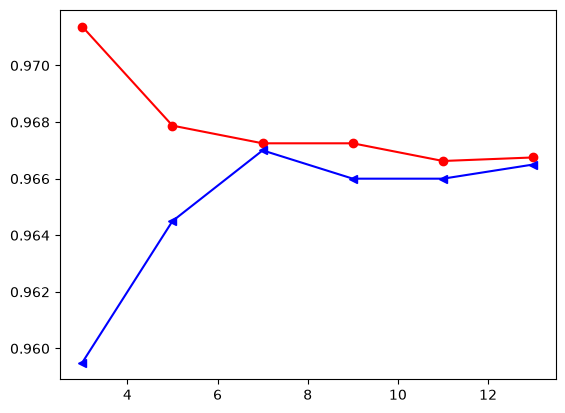

In [120]:
plt.plot(k_values,train_pred_val,color='red',marker='o')
plt.plot(k_values,test_pred_val,color='blue',marker='<')
plt.show()